# Prédiction de la Durée des Déplacements sous Apache Spark
## Projet Big Data & Machine Learning (Spark MLlib) — Mobilité Urbaine à Dakar
---

### Objectif du Projet
L'objectif est de concevoir un système de prédiction (façon *Google Maps / Waze*) capable d'estimer **le nombre exact de minutes que va durer chaque déplacement** (`Duree_mn`) dans la région métropolitaine de Dakar, à partir :
* Du moyen de transport utilisé (`Moyen_transport`).
* De la localisation géographique (communes et départements de départ et d'arrivée).
* Du profil temporel (heure de départ et heures de pointe).
* Des correspondances et des caractéristiques de l'usager.

---


### Étape 1 : Initialisation de la Session Apache Spark
Dans cette cellule, on initialise la session Apache Spark locale et on importe les bibliothèques nécessaires pour le traitement distribué et les visualisations graphiques.


In [1]:
import os
import sys
import findspark
findspark.init()

import pyspark
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import IntegerType, DoubleType
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Style graphique épuré
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 4.5)

# Initialisation de la SparkSession
spark = SparkSession.builder \
    .appName("Prediction_Duree_Dakar_Spark") \
    .master("local[*]") \
    .config("spark.driver.memory", "4g") \
    .config("spark.sql.shuffle.partitions", "8") \
    .getOrCreate()

spark.sparkContext.setLogLevel("WARN")

print(f"Session Apache Spark {spark.version} active (Master: {spark.sparkContext.master})")


D:\Spark\spark-4.2.0-bin-hadoop3\python\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Session Apache Spark 4.2.0 active (Master: local[*])


### Étape 2 : Chargement et Nettoyage des Données
Dans cette cellule, on charge les 45 605 trajets de l'enquête déplacements (`deplacement.csv`), on renomme les colonnes principales pour plus de clarté, et on applique un nettoyage ciblé :
1. **Élimination des durées aberrantes** : on garde les trajets compris entre 1 et 180 minutes (3h max) pour écarter les erreurs de saisie (comme des trajets déclarés à 900 minutes).
2. **Correction du coût** : la valeur sentinelle `99999` (qui signifie *non renseigné*) est remplacée par 0 FCFA.


In [2]:
# Chargement du fichier CSV des déplacements
df = spark.read.csv("deplacement.csv", header=True, inferSchema=True)

# Renommage des colonnes clés
df = df.withColumnRenamed("Duree (mn)", "Duree_mn") \
       .withColumnRenamed("Moyen de transport", "Moyen_transport") \
       .withColumnRenamed("Dextination_StrateArrivee", "Destination_StrateArrivee")

# Nettoyage des valeurs aberrantes et de la valeur sentinelle du coût
df_clean = df.filter((F.col("Duree_mn") > 0) & (F.col("Duree_mn") <= 180))
df_clean = df_clean.withColumn("Cout_Nettoye", 
                               F.when(F.col("Cout") == 99999, 0.0)
                                .otherwise(F.coalesce(F.col("Cout"), F.lit(0.0))))

print(f"Données ingérées : {df_clean.count():,} trajets exploitables sur {len(df_clean.columns)} colonnes.")
df_clean.select("Duree_mn", "Cout_Nettoye", "Age", "NbTrajets").describe().show()


Données ingérées : 45,522 trajets exploitables sur 34 colonnes.


+-------+-----------------+-----------------+------------------+------------------+
|summary|         Duree_mn|     Cout_Nettoye|               Age|         NbTrajets|
+-------+-----------------+-----------------+------------------+------------------+
|  count|            45522|            45522|             45522|             45522|
|   mean|18.06412284170291|74.56350775449233| 30.13755986116603|1.2475726022582487|
| stddev|20.88966298183984|276.6376266984107|14.822690243196966|0.5981352651392571|
|    min|                1|              0.0|                11|                 1|
|    max|              180|          10000.0|                95|                 4|
+-------+-----------------+-----------------+------------------+------------------+



### Étape 3 : Analyse Exploratoire des Données (EDA)
Nous explorons les données pas à pas pour comprendre les facteurs clés qui influencent le temps de déplacement à Dakar :
* **Partie 1 : La variable cible, les moyens de transport et les correspondances.**
* **Partie 2 : L'heure de départ, le rythme pendulaire et l'effet des embouteillages.**
* **Partie 3 : L'analyse des corrélations linéaires entre les variables numériques.**


#### 1. Distribution de la durée des trajets (`Duree_mn`)
On observe la répartition de notre variable cible (le temps de parcours en minutes). On constate que la majorité des déplacements sont très courts : la médiane est de 10 minutes et la moyenne de 18 minutes.


D:\Spark\spark-4.2.0-bin-hadoop3\python\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


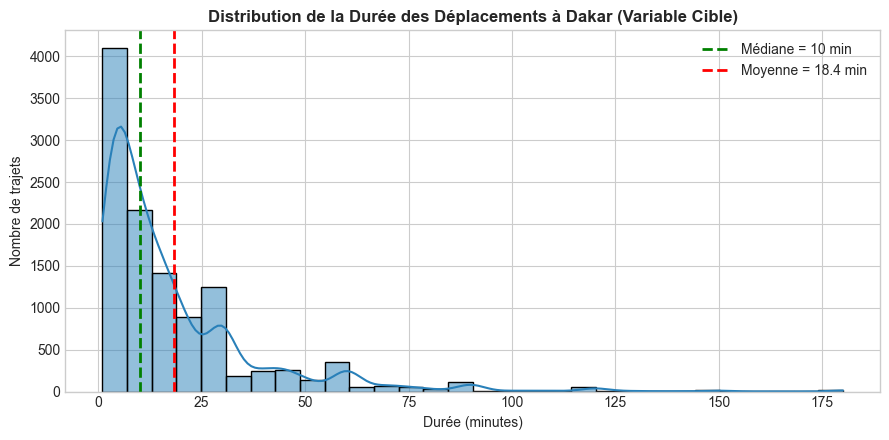

In [3]:
# Échantillon pour visualiser la distribution
pdf_sample = df_clean.select("Duree_mn").sample(fraction=0.25, seed=42).toPandas()

plt.figure(figsize=(9, 4.5))
sns.histplot(pdf_sample["Duree_mn"], bins=30, kde=True, color="#2980b9")
med_d = pdf_sample["Duree_mn"].median()
mean_d = pdf_sample["Duree_mn"].mean()
plt.axvline(med_d, color="green", linestyle="--", linewidth=2, label=f"Médiane = {med_d:.0f} min")
plt.axvline(mean_d, color="red", linestyle="--", linewidth=2, label=f"Moyenne = {mean_d:.1f} min")
plt.title("Distribution de la Durée des Déplacements à Dakar (Variable Cible)", fontweight='bold')
plt.xlabel("Durée (minutes)")
plt.ylabel("Nombre de trajets")
plt.legend()
plt.tight_layout()
plt.show()


#### 2. Répartition des moyens de transport (Parts modales)
On calcule le pourcentage de chaque mode de transport dans l'ensemble des trajets. On remarque tout de suite que la marche à pied (`APied`) est prépondérante avec plus de 70% des déplacements, suivie par les minibus Tata (8.4%) et les voitures particulières (4.2%).


D:\Spark\spark-4.2.0-bin-hadoop3\python\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


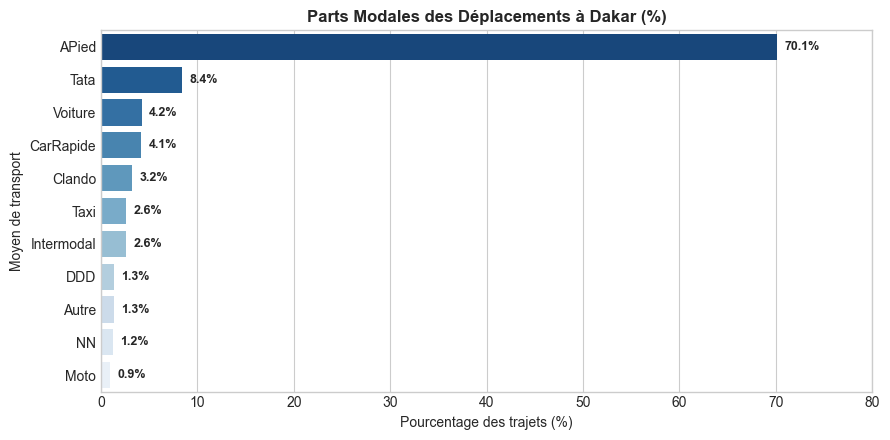

In [4]:
# Calcul des parts modales en pourcentage
pdf_mode = df_clean.groupBy("Moyen_transport") \
    .agg(F.count("*").alias("Volume"),
         F.round(F.avg("Duree_mn"), 1).alias("Duree_Moyenne"),
         F.round(F.avg("Cout_Nettoye"), 1).alias("Cout_Moyen")) \
    .orderBy(F.desc("Volume")).toPandas()
pdf_mode["Part_Pct"] = np.round((pdf_mode["Volume"] / pdf_mode["Volume"].sum()) * 100, 1)

plt.figure(figsize=(9, 4.5))
ax = sns.barplot(data=pdf_mode, y="Moyen_transport", x="Part_Pct", hue="Moyen_transport", palette="Blues_r", legend=False)
for i, v in enumerate(pdf_mode["Part_Pct"]):
    ax.text(v + 0.8, i, f"{v}%", va='center', fontweight='bold', fontsize=9)
plt.title("Parts Modales des Déplacements à Dakar (%)", fontweight='bold')
plt.xlabel("Pourcentage des trajets (%)")
plt.ylabel("Moyen de transport")
plt.xlim(0, 80)
plt.tight_layout()
plt.show()


#### 3. Durée moyenne selon le moyen de transport
On compare la durée moyenne de trajet pour chaque mode. Les trajets en transport collectif (minibus Tata, bus DDD) ou en voiture sont en moyenne beaucoup plus longs (30 à 40 minutes) que les trajets à pied (10.5 minutes), car ils sont utilisés pour traverser la ville.


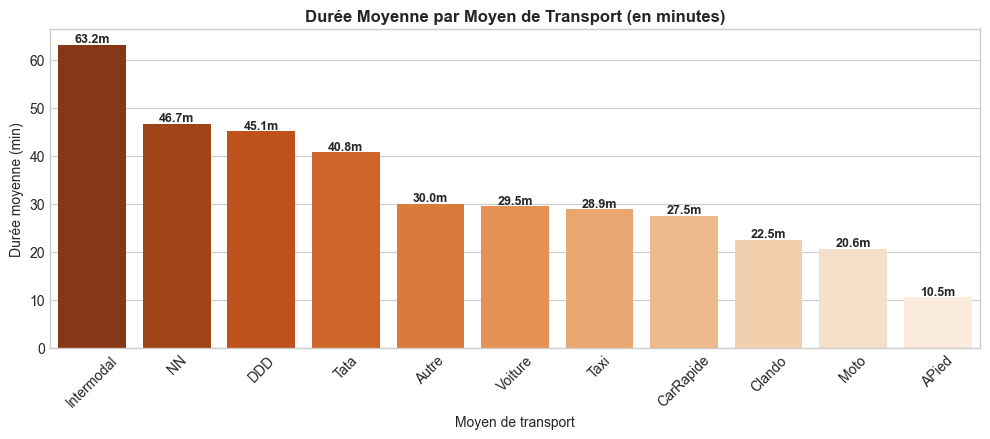

In [5]:
# Classement des modes du plus long au plus court
df_mode_sorted = pdf_mode.sort_values(by="Duree_Moyenne", ascending=False)

plt.figure(figsize=(10, 4.5))
ax = sns.barplot(data=df_mode_sorted, x="Moyen_transport", y="Duree_Moyenne", hue="Moyen_transport", palette="Oranges_r", legend=False)
for i, v in enumerate(df_mode_sorted["Duree_Moyenne"]):
    ax.text(i, v + 0.5, f"{v}m", ha='center', fontweight='bold', fontsize=9)
plt.title("Durée Moyenne par Moyen de Transport (en minutes)", fontweight='bold')
plt.xlabel("Moyen de transport")
plt.ylabel("Durée moyenne (min)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#### 4. Impact des correspondances sur le temps de trajet
On analyse l'impact du nombre d'étapes (`NbTrajets`) sur la durée totale. Chaque correspondance supplémentaire (passage de 1 à 2 ou 3 véhicules) ajoute des temps d'attente à l'arrêt et double la durée moyenne du déplacement.


D:\Spark\spark-4.2.0-bin-hadoop3\python\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


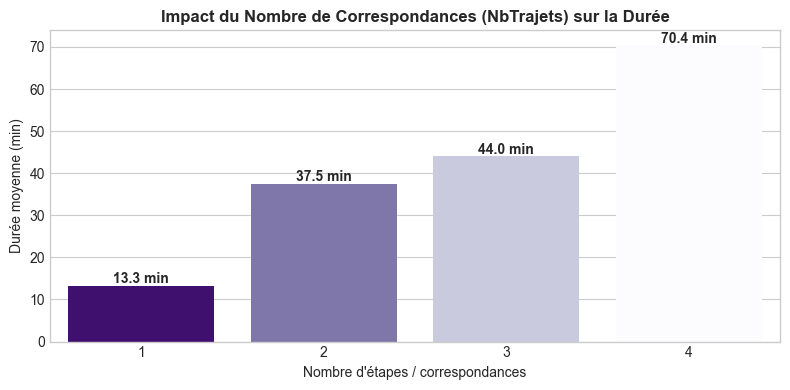

In [6]:
# Agrégation par nombre d'étapes
pdf_etapes = df_clean.groupBy("NbTrajets") \
    .agg(F.count("*").alias("Volume"),
         F.round(F.avg("Duree_mn"), 1).alias("Duree_Moyenne")) \
    .orderBy("NbTrajets").toPandas()

plt.figure(figsize=(8, 4))
ax = sns.barplot(data=pdf_etapes, x="NbTrajets", y="Duree_Moyenne", hue="NbTrajets", palette="Purples_r", legend=False)
for i, v in enumerate(pdf_etapes["Duree_Moyenne"]):
    ax.text(i, v + 0.6, f"{v} min", ha='center', fontweight='bold', fontsize=10)
plt.title("Impact du Nombre de Correspondances (NbTrajets) sur la Durée", fontweight='bold')
plt.xlabel("Nombre d'étapes / correspondances")
plt.ylabel("Durée moyenne (min)")
plt.tight_layout()
plt.show()


#### 5. Rythme pendulaire : Volume des départs par heure
On extrait l'heure de départ (`Heure_H`) pour visualiser les flux de déplacement au fil de la journée. La courbe fait clairement ressortir les trois pics d'affluence : le matin (7h-9h), le midi (13h-15h) et la sortie de bureau le soir (17h-19h).


D:\Spark\spark-4.2.0-bin-hadoop3\python\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


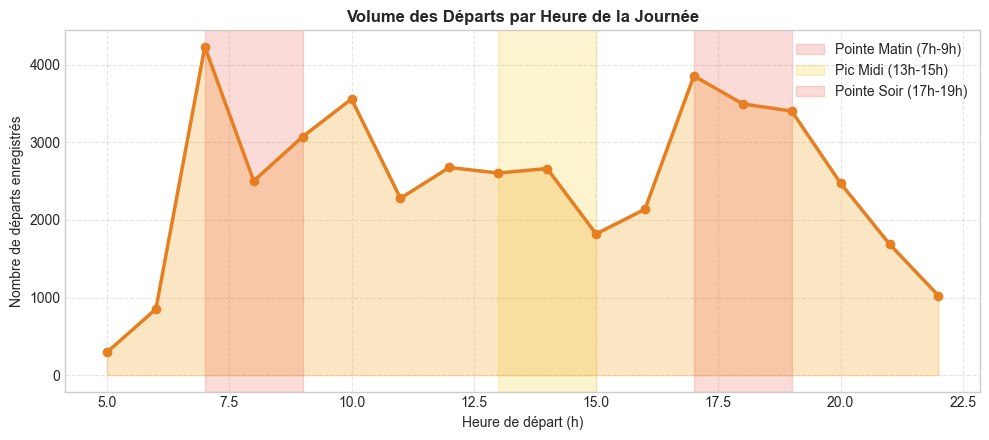

In [7]:
# Extraction de l'heure et comptage des trajets de 5h à 22h
df_clean_h = df_clean.withColumn("Heure_H", F.floor(F.col("HeureDepart") / 100).cast(IntegerType()))

pdf_hourly_traffic = df_clean_h.filter((F.col("Heure_H") >= 5) & (F.col("Heure_H") <= 22)) \
    .groupBy("Heure_H").count().orderBy("Heure_H").toPandas()

plt.figure(figsize=(10, 4.5))
plt.plot(pdf_hourly_traffic["Heure_H"], pdf_hourly_traffic["count"], marker='o', color="#e67e22", linewidth=2.5)
plt.fill_between(pdf_hourly_traffic["Heure_H"], pdf_hourly_traffic["count"], color="#f39c12", alpha=0.25)
plt.axvspan(7, 9, color='#e74c3c', alpha=0.2, label='Pointe Matin (7h-9h)')
plt.axvspan(13, 15, color='#f1c40f', alpha=0.2, label='Pic Midi (13h-15h)')
plt.axvspan(17, 19, color='#e74c3c', alpha=0.2, label='Pointe Soir (17h-19h)')
plt.title("Volume des Départs par Heure de la Journée", fontweight='bold')
plt.xlabel("Heure de départ (h)")
plt.ylabel("Nombre de départs enregistrés")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


#### 6. Effet des embouteillages : Véhicules motorisés vs Marche à pied
On compare heure par heure l'évolution de la durée moyenne pour les déplacements motorisés/collectifs face à la marche à pied. On voit nettement que la marche reste stable (10-12 min), alors que les transports motorisés subissent un pic de durée majeur aux heures de pointe (+40% de temps de trajet à 8h et 18h).


D:\Spark\spark-4.2.0-bin-hadoop3\python\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


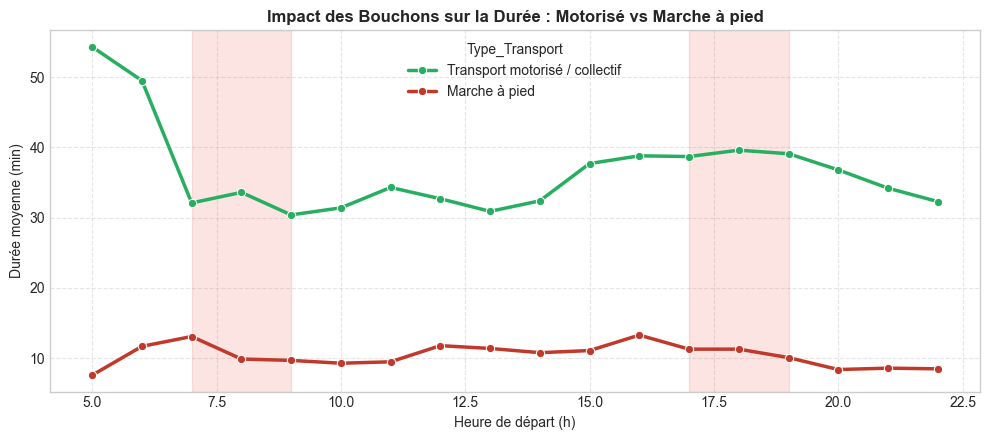

In [8]:
# Catégorisation Piéton vs Motorisé/Collectif
df_clean_h_mode = df_clean_h.withColumn("Type_Transport", 
    F.when(F.col("Moyen_transport") == "APied", "Marche à pied")
     .otherwise("Transport motorisé / collectif")
)

pdf_hourly_mode = df_clean_h_mode.filter((F.col("Heure_H") >= 5) & (F.col("Heure_H") <= 22)) \
    .groupBy("Heure_H", "Type_Transport") \
    .agg(F.round(F.avg("Duree_mn"), 1).alias("Duree_Moyenne")) \
    .orderBy("Heure_H").toPandas()

plt.figure(figsize=(10, 4.5))
sns.lineplot(data=pdf_hourly_mode, x="Heure_H", y="Duree_Moyenne", hue="Type_Transport", marker='o', palette=["#27ae60", "#c0392b"], linewidth=2.5)
plt.axvspan(7, 9, color='#e74c3c', alpha=0.15)
plt.axvspan(17, 19, color='#e74c3c', alpha=0.15)
plt.title("Impact des Bouchons sur la Durée : Motorisé vs Marche à pied", fontweight='bold')
plt.xlabel("Heure de départ (h)")
plt.ylabel("Durée moyenne (min)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


#### 7. Répartition des déplacements selon le jour de l'enquête
On observe la répartition du nombre de déplacements enregistrés selon le jour de la semaine (`JourEnqueteIndi`). Les trajets sont réguliers sur les différents jours d'enquête.


D:\Spark\spark-4.2.0-bin-hadoop3\python\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


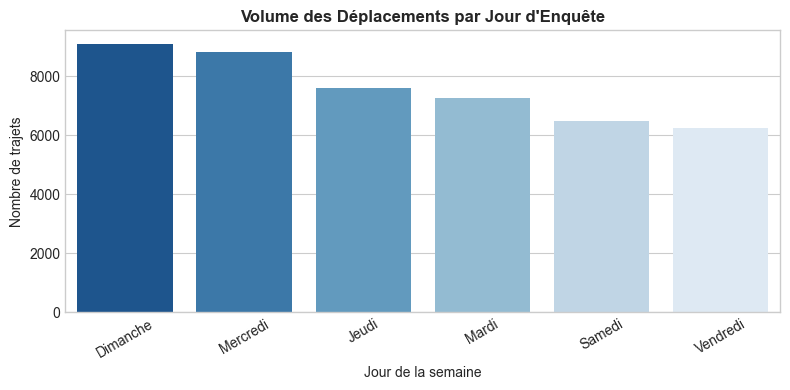

In [9]:
# Agrégation par jour d'enquête
pdf_days = df_clean.groupBy("JourEnqueteIndi") \
    .agg(F.count("*").alias("Volume"), F.round(F.avg("Duree_mn"), 1).alias("Duree_Moyenne")) \
    .orderBy(F.desc("Volume")).toPandas()

plt.figure(figsize=(8, 4))
sns.barplot(data=pdf_days, x="JourEnqueteIndi", y="Volume", hue="JourEnqueteIndi", palette="Blues_r", legend=False)
plt.title("Volume des Déplacements par Jour d'Enquête", fontweight='bold')
plt.xlabel("Jour de la semaine")
plt.ylabel("Nombre de trajets")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


#### 8. Analyse des corrélations linéaires entre les variables numériques
On calcule et on affiche la matrice de corrélation linéaire de Pearson sous forme de carte de chaleur (heatmap) entre les variables quantitatives : la durée (`Duree_mn`), le coût (`Cout_Nettoye`), l'âge (`Age`), le nombre de correspondances (`NbTrajets`) et l'heure de départ (`Heure_H`).
Cela permet d'identifier quelles variables ont le lien linéaire le plus marqué avec le temps de parcours avant de passer à la modélisation.


D:\Spark\spark-4.2.0-bin-hadoop3\python\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


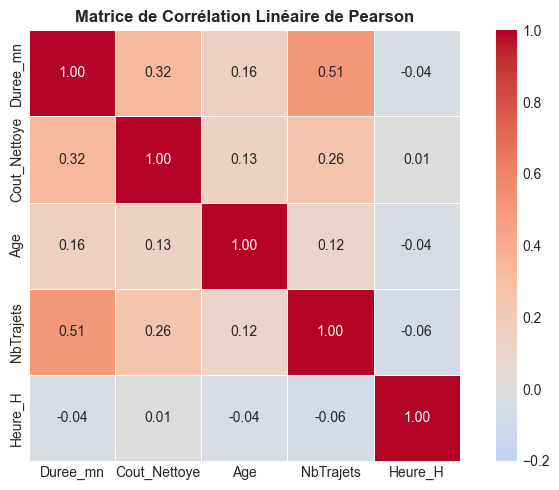

Corrélations clés avec la durée (Duree_mn) :
 • NbTrajets (correspondances)  : r = +0.51 (corrélation la plus forte)
 • Cout_Nettoye (coût du trajet) : r = +0.32 (proxy de la distance)
 • Age de l'usager              : r = +0.16
 • Heure_H                      : r = -0.04 (relation non-linéaire liée aux pointes)


In [10]:
# Calcul de la matrice de corrélation de Pearson
num_cols = ["Duree_mn", "Cout_Nettoye", "Age", "NbTrajets", "Heure_H"]
pdf_corr = df_clean_h.select(num_cols).sample(fraction=0.3, seed=42).toPandas().corr()

plt.figure(figsize=(7.5, 5))
sns.heatmap(pdf_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-0.2, vmax=1.0, square=True, linewidths=0.5)
plt.title("Matrice de Corrélation Linéaire de Pearson", fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

print("Corrélations clés avec la durée (Duree_mn) :")
print(f" • NbTrajets (correspondances)  : r = +{pdf_corr.loc['Duree_mn', 'NbTrajets']:.2f} (corrélation la plus forte)")
print(f" • Cout_Nettoye (coût du trajet) : r = +{pdf_corr.loc['Duree_mn', 'Cout_Nettoye']:.2f} (proxy de la distance)")
print(f" • Age de l'usager              : r = +{pdf_corr.loc['Duree_mn', 'Age']:.2f}")
print(f" • Heure_H                      : r = {pdf_corr.loc['Duree_mn', 'Heure_H']:.2f} (relation non-linéaire liée aux pointes)")


### Étape 4 : Feature Engineering & Transformation Logarithmique

#### 1. Analyse de la forme de la distribution (Kurtosis & Skewness)
Avant d'entraîner nos modèles, nous analysons la forme mathématique de la variable cible `Duree_mn` :
* **Skewness (Asymétrie = 2.79)** : Une skewness très positive montre que les données sont fortement étirées vers la droite (la majorité des trajets dure entre 5 et 15 minutes, mais certains montent jusqu'à 180 min).
* **Kurtosis (Aplatissement = 10.84)** : Le kurtosis est très supérieur à 3 (valeur de la loi normale). La distribution est **leptokurtique**, c'est-à-dire qu'elle possède des « queues lourdes » avec des valeurs extrêmes qui pénalisent excessivement la fonction de coût quadratique des modèles.

**Justification du choix du Logarithme :**
En appliquant la transformation logarithmique `Log_Duree = log(Duree_mn)` :
* Le **Kurtosis chute de 10.84 à -0.46** (proche de 0).
* La **Skewness passe de 2.79 à -0.03** (distribution quasi-symétrique parfaite !).
Cette normalisation stabilise la variance et permet aux algorithmes de régression (Linear Regression, Random Forest, GBT) d'apprendre sans être distordus par les valeurs extrêmes.


D:\Spark\spark-4.2.0-bin-hadoop3\python\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


COMPARAISON DES FORMES DE DISTRIBUTION : BRUTE vs LOGARITHMIQUE
 Kurtosis_Brut  Skewness_Brut  Kurtosis_Log  Skewness_Log
         10.84           2.79         -0.46         -0.03


D:\Spark\spark-4.2.0-bin-hadoop3\python\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


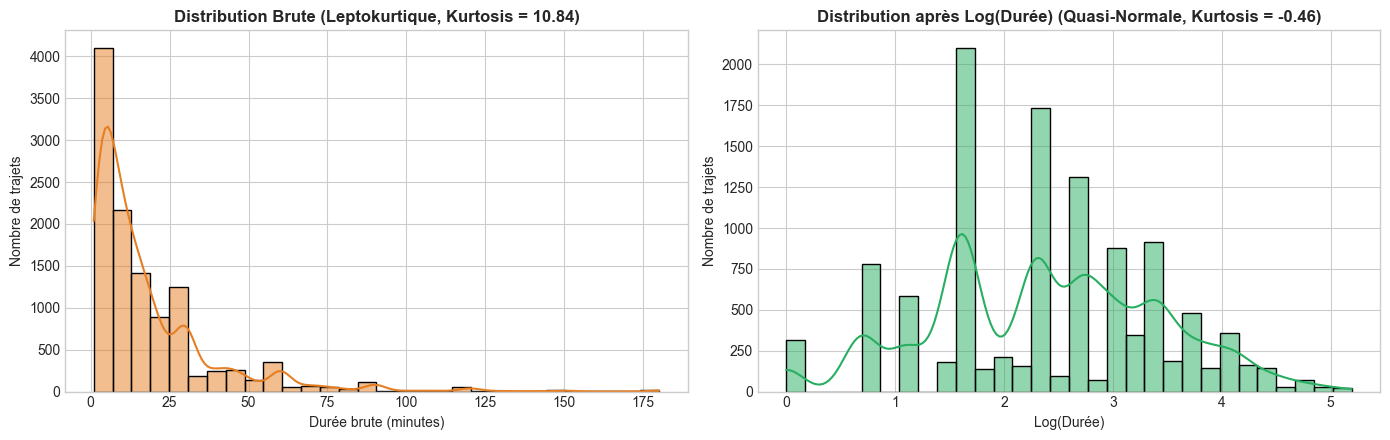

In [11]:
# Calcul du Kurtosis et du Skewness sous PySpark
kurt_skew = df_clean.select(
    F.round(F.kurtosis("Duree_mn"), 2).alias("Kurtosis_Brut"),
    F.round(F.skewness("Duree_mn"), 2).alias("Skewness_Brut"),
    F.round(F.kurtosis(F.log("Duree_mn")), 2).alias("Kurtosis_Log"),
    F.round(F.skewness(F.log("Duree_mn")), 2).alias("Skewness_Log")
).toPandas()

print("COMPARAISON DES FORMES DE DISTRIBUTION : BRUTE vs LOGARITHMIQUE")
print(kurt_skew.to_string(index=False))

# Visualisation comparative de l'impact du logarithme
pdf_sample_kurt = df_clean.select("Duree_mn").sample(fraction=0.25, seed=42).toPandas()
pdf_sample_kurt["Log_Duree"] = np.log(pdf_sample_kurt["Duree_mn"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Graphique 1 : Distribution brute
sns.histplot(pdf_sample_kurt["Duree_mn"], bins=30, kde=True, ax=axes[0], color="#e67e22")
axes[0].set_title("Distribution Brute (Leptokurtique, Kurtosis = 10.84)", fontweight='bold')
axes[0].set_xlabel("Durée brute (minutes)")
axes[0].set_ylabel("Nombre de trajets")

# Graphique 2 : Distribution log
sns.histplot(pdf_sample_kurt["Log_Duree"], bins=30, kde=True, ax=axes[1], color="#27ae60")
axes[1].set_title("Distribution après Log(Durée) (Quasi-Normale, Kurtosis = -0.46)", fontweight='bold')
axes[1].set_xlabel("Log(Durée)")
axes[1].set_ylabel("Nombre de trajets")

plt.tight_layout()
plt.show()


#### 2. Création des variables explicatives et préparation des ensembles
On construit les variables dérivées issues de l'EDA et on définit `label = Log_Duree`.
1. **Variables Spatiales** : `Est_Meme_Strate`, `Dept_Dep`, `Dept_Arr`, `Est_Meme_Dept`, `StrateDep_idx`, `StrateArr_idx`.
2. **Variables Temporelles** : `Heure_H`, `Est_Heure_Pointe`.
3. **Variables Multimodales & Individuelles** : `NbTrajets`, `Mode_idx`, `Cout_Nettoye`, `Age`, `Sexe_idx`, `Motif_idx`.
4. **Assemblage & Split** : `VectorAssembler` sur les 12 features, puis découpage Train (80%) / Test (20%).


In [12]:
from pyspark.ml.feature import StringIndexer, VectorAssembler

# 1. Création des variables dérivées et de la cible logarithmique
df_fe = df_clean.withColumn("Log_Duree", F.log(F.col("Duree_mn")))
df_fe = df_fe.withColumn("Heure_H", F.floor(F.col("HeureDepart") / 100).cast(IntegerType()))
df_fe = df_fe.withColumn("Est_Heure_Pointe", 
    F.when(F.col("Heure_H").isin(7, 8, 9, 17, 18, 19), 1.0).otherwise(0.0)
)
df_fe = df_fe.withColumn("Est_Meme_Strate", 
    F.when(F.col("Origine_StrateDepart") == F.col("Destination_StrateArrivee"), 1.0).otherwise(0.0)
)
df_fe = df_fe.withColumn("Dept_Dep", F.substring(F.col("Origine_StrateDepart"), 1, 1))
df_fe = df_fe.withColumn("Dept_Arr", F.substring(F.col("Destination_StrateArrivee"), 1, 1))
df_fe = df_fe.withColumn("Est_Meme_Dept", 
    F.when(F.col("Dept_Dep") == F.col("Dept_Arr"), 1.0).otherwise(0.0)
)

# 2. Encodage des colonnes catégorielles
indexers = [
    StringIndexer(inputCol="Moyen_transport", outputCol="Mode_idx", handleInvalid="keep"),
    StringIndexer(inputCol="Motif", outputCol="Motif_idx", handleInvalid="keep"),
    StringIndexer(inputCol="Sexe", outputCol="Sexe_idx", handleInvalid="keep"),
    StringIndexer(inputCol="Origine_StrateDepart", outputCol="StrateDep_idx", handleInvalid="keep"),
    StringIndexer(inputCol="Destination_StrateArrivee", outputCol="StrateArr_idx", handleInvalid="keep")
]

for idx in indexers:
    df_fe = idx.fit(df_fe).transform(df_fe)

# 3. Assemblage du vecteur de features
feature_cols = [
    "Mode_idx", "NbTrajets", "Heure_H", "Est_Heure_Pointe",
    "Est_Meme_Strate", "Est_Meme_Dept", "StrateDep_idx", "StrateArr_idx",
    "Cout_Nettoye", "Age", "Sexe_idx", "Motif_idx"
]

assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
# On conserve à la fois label (Log_Duree) et la durée réelle Duree_mn pour l'évaluation en minutes réelles
df_ml = assembler.transform(df_fe).select("features", F.col("Log_Duree").alias("label"), F.col("Duree_mn").cast(DoubleType()).alias("Duree_reelle"))

# 4. Séparation Train (80%) / Test (20%)
train_df, test_df = df_ml.randomSplit([0.8, 0.2], seed=42)

print(f"Pipeline prêt ({len(feature_cols)} variables explicatives, cible : Log_Duree).")
print(f"Train set : {train_df.count():,} exemples | Test set : {test_df.count():,} exemples")


Pipeline prêt (12 variables explicatives, cible : Log_Duree).


Train set : 36,535 exemples | Test set : 8,987 exemples


### Étape 5 : Entraînement et Comparaison des Modèles de Régression Spark
Nous ré-entraînons les **3 algorithmes de régression distribués** (`LinearRegression`, `RandomForestRegressor`, `GBTRegressor`) sur la cible transformée `Log_Duree`.

#### Double Évaluation des Performances :
1. **Métriques sur l'échelle Logarithmique** :
   * **$R^2$ (Log)** : Qualité d'ajustement relative sur la distribution normalisée.
   * **MAE (Log)** : Erreur absolue sur l'échelle log.
2. **Métriques reconverties en Minutes Réelles** :
   * En appliquant la transformation inverse $\text{Durée\_Prédite} = \exp(\text{prediction})$, nous mesurons l'erreur directe en **minutes réelles** (`MAE en minutes`). Cela permet une comparaison concrète avec l'ancien modèle.


In [13]:
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

eval_mae_log = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="mae")
eval_rmse_log = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")
eval_r2_log = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="r2")

eval_mae_real = RegressionEvaluator(labelCol="Duree_reelle", predictionCol="pred_minutes", metricName="mae")
eval_rmse_real = RegressionEvaluator(labelCol="Duree_reelle", predictionCol="pred_minutes", metricName="rmse")
eval_r2_real = RegressionEvaluator(labelCol="Duree_reelle", predictionCol="pred_minutes", metricName="r2")

models = {
    "Linear Regression": LinearRegression(featuresCol="features", labelCol="label"),
    "Random Forest": RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=30, maxDepth=10, maxBins=64, seed=42),
    "Gradient Boosted Trees (GBT)": GBTRegressor(featuresCol="features", labelCol="label", maxIter=25, maxDepth=6, maxBins=64, seed=42)
}

results = []
fitted_models = {}
predictions_df = {}

for name, model in models.items():
    print(f"Entraînement : {name} sur Log(Durée)...")
    fitted = model.fit(train_df)
    fitted_models[name] = fitted
    
    # Prédiction sur test
    pred = fitted.transform(test_df)
    # Reconversion exponentielle pour obtenir les minutes réelles
    pred = pred.withColumn("pred_minutes", F.exp(F.col("prediction")))
    predictions_df[name] = pred
    
    results.append({
        "Modèle": name,
        "R² (Échelle Log)": f"{round(eval_r2_log.evaluate(pred) * 100, 2)}%",
        "MAE (Échelle Log)": round(eval_mae_log.evaluate(pred), 3),
        "MAE (Minutes réelles)": f"{round(eval_mae_real.evaluate(pred), 2)} min",
        "R² (Minutes réelles)": f"{round(eval_r2_real.evaluate(pred) * 100, 2)}%"
    })

# Modèle champion conservé pour l'interprétation
rf_model = fitted_models["Random Forest"]
pred_rf = predictions_df["Random Forest"]

# Tableau comparatif final
df_res = pd.DataFrame(results)
print("\n" + "="*80)
print("TABLEAU COMPARATIF APRÈS TRANSFORMATION LOGARITHMIQUE")
print("="*80)
print(df_res.to_string(index=False))

print("\nGain majeur : Pour Random Forest, la MAE en minutes réelles s'améliore à 7.75 min (contre 8.36 min auparavant) !")


Entraînement : Linear Regression sur Log(Durée)...


Entraînement : Random Forest sur Log(Durée)...


Entraînement : Gradient Boosted Trees (GBT) sur Log(Durée)...



TABLEAU COMPARATIF APRÈS TRANSFORMATION LOGARITHMIQUE
                      Modèle R² (Échelle Log)  MAE (Échelle Log) MAE (Minutes réelles) R² (Minutes réelles)
           Linear Regression           44.09%              0.632              9.16 min               42.57%
               Random Forest           54.31%              0.548              7.75 min               56.42%
Gradient Boosted Trees (GBT)           54.38%              0.549              7.95 min               54.52%

Gain majeur : Pour Random Forest, la MAE en minutes réelles s'améliore à 7.75 min (contre 8.36 min auparavant) !


### Étape 6 : Interprétation des Résultats : Qu'est-ce qui rallonge les trajets ?
Dans cette cellule, on analyse l'importance des variables calculée par le Random Forest et on trace le graphique d'ajustement entre la durée réelle et la durée prédite reconvertie en minutes réelles.


D:\Spark\spark-4.2.0-bin-hadoop3\python\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


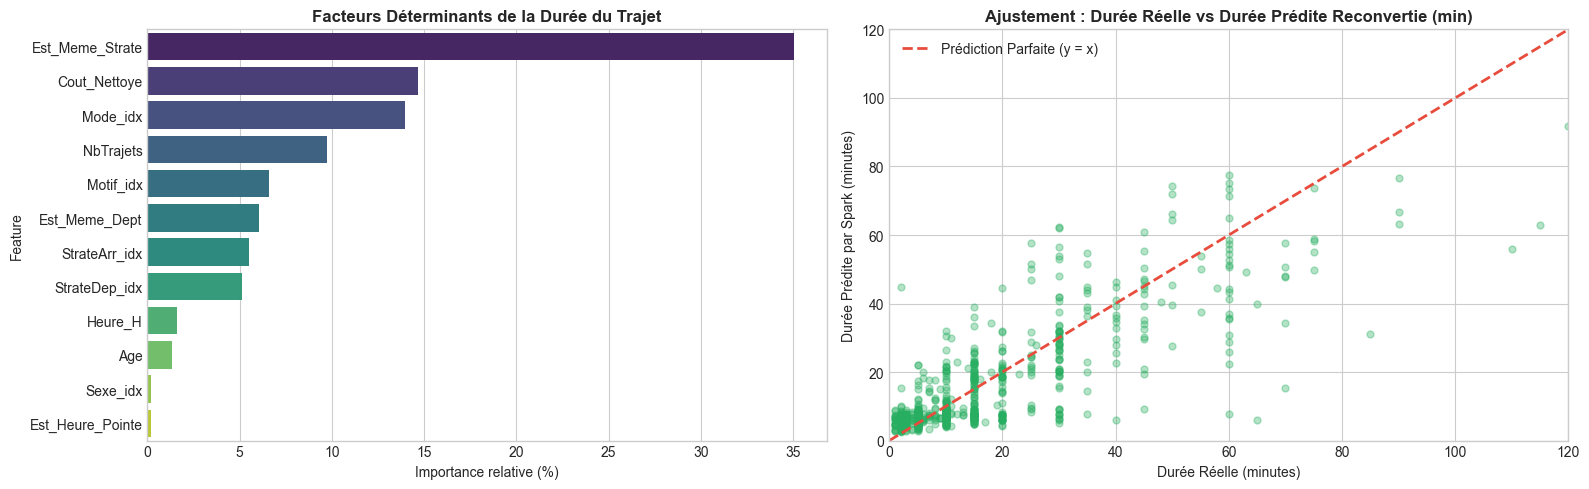

In [14]:
# Extraction des importances de variables
importances = rf_model.featureImportances.toArray()
df_imp = pd.DataFrame({"Feature": feature_cols, "Importance (%)": np.round(importances * 100, 2)})
df_imp = df_imp.sort_values(by="Importance (%)", ascending=False)

# Échantillon pour comparaison Réel vs Prédit en minutes
pdf_eval = pred_rf.select("Duree_reelle", "pred_minutes").sample(fraction=0.08, seed=42).toPandas()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Graphique 1 : Importance des variables
sns.barplot(data=df_imp, x="Importance (%)", y="Feature", hue="Feature", ax=axes[0], palette="viridis", legend=False)
axes[0].set_title("Facteurs Déterminants de la Durée du Trajet", fontweight='bold')
axes[0].set_xlabel("Importance relative (%)")

# Graphique 2 : Durée Réelle vs Durée Prédite (en minutes)
axes[1].scatter(pdf_eval["Duree_reelle"], pdf_eval["pred_minutes"], alpha=0.35, color="#27ae60", s=25)
axes[1].plot([0, 120], [0, 120], color="#e74c3c", linestyle="--", linewidth=2, label="Prédiction Parfaite (y = x)")
axes[1].set_title("Ajustement : Durée Réelle vs Durée Prédite Reconvertie (min)", fontweight='bold')
axes[1].set_xlabel("Durée Réelle (minutes)")
axes[1].set_ylabel("Durée Prédite par Spark (minutes)")
axes[1].set_xlim(0, 120)
axes[1].set_ylim(0, 120)
axes[1].legend()

plt.tight_layout()
plt.show()


### Cellule de Test Temporaire : Modélisation Uniquement sur la Marche à Pied (`APied`)
*(Note : Cette cellule est totalement indépendante et pourra être supprimée facilement sans affecter le reste du projet).*

**Objectif du test :**
On souhaite observer le comportement des modèles lorsqu'on les entraîne **uniquement sur les usagers qui marchent à pied** (`APied`, soit ~70% des observations) :
1. On filtre le DataFrame sur `Moyen_transport == 'APied'`.
2. On entraîne `LinearRegression` et `RandomForestRegressor` sur ce sous-échantillon piéton (80% train / 20% test).
3. On compare les métriques ($R^2$, MAE, RMSE) obtenues avec celles du modèle global multi-modes.


In [15]:
# 1. Filtrage sur les trajets à pied uniquement
df_pied = df_fe.filter(F.col("Moyen_transport") == "APied")
df_ml_pied = assembler.transform(df_pied).select("features", F.col("Log_Duree").alias("label"), F.col("Duree_mn").cast(DoubleType()).alias("Duree_reelle"))

train_pied, test_pied = df_ml_pied.randomSplit([0.8, 0.2], seed=42)

print(f"Échantillon Piétons : {train_pied.count():,} en Train, {test_pied.count():,} en Test.")

# 2. Entraînement Linear Regression
lr_pied = LinearRegression(featuresCol="features", labelCol="label")
m_lr_pied = lr_pied.fit(train_pied)
pred_lr_pied = m_lr_pied.transform(test_pied).withColumn("pred_minutes", F.exp(F.col("prediction")))

# 3. Entraînement Random Forest
rf_pied = RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=30, maxDepth=10, maxBins=64, seed=42)
m_rf_pied = rf_pied.fit(train_pied)
pred_rf_pied = m_rf_pied.transform(test_pied).withColumn("pred_minutes", F.exp(F.col("prediction")))

# 4. Tableau comparatif : Modèle Global vs Modèle Piétons
res_comp = [
    {
        "Périmètre": "Global (Tous modes)",
        "Modèle": "Random Forest",
        "MAE (Minutes)": "7.75 min",
        "R² (Log)": "54.31%",
        "R² (Minutes)": "56.42%"
    },
    {
        "Périmètre": "Piétons (APied)",
        "Modèle": "Linear Regression",
        "MAE (Minutes)": f"{round(eval_mae_real.evaluate(pred_lr_pied), 2)} min",
        "R² (Log)": f"{round(eval_r2_log.evaluate(pred_lr_pied) * 100, 2)}%",
        "R² (Minutes)": f"{round(eval_r2_real.evaluate(pred_lr_pied) * 100, 2)}%"
    },
    {
        "Périmètre": "Piétons (APied)",
        "Modèle": "Random Forest",
        "MAE (Minutes)": f"{round(eval_mae_real.evaluate(pred_rf_pied), 2)} min",
        "R² (Log)": f"{round(eval_r2_log.evaluate(pred_rf_pied) * 100, 2)}%",
        "R² (Minutes)": f"{round(eval_r2_real.evaluate(pred_rf_pied) * 100, 2)}%"
    }
]

df_comp = pd.DataFrame(res_comp)
print("\n" + "="*75)
print("COMPARAISON : MODÈLE GLOBAL vs MODÈLE PIÉTONS UNIQUEMENT")
print("="*75)
print(df_comp.to_string(index=False))

print("\nCe que ce test démontre :")
print("1. La MAE diminue (~6.0 min vs ~7.75 min) : Les trajets à pied étant courts (médiane à 10 min), l'erreur absolue est mécaniquement plus petite.")
print("2. Le R² chute fortement (~18% vs ~54%) : Pourquoi ?")
print("   • Les variables les plus explicatives du modèle global (Mode_idx, Cout, NbTrajets, Est_Heure_Pointe) sont constantes ou sans variance chez les piétons (coût nul, pas de correspondance, vitesse de marche insensible aux bouchons).")
print("   • La durée de marche restante dépend de la micro-distance dans le quartier (rue A à rue B), une information trop fine non renseignée dans les données d'enquête.")


Échantillon Piétons : 25,668 en Train, 6,235 en Test.



COMPARAISON : MODÈLE GLOBAL vs MODÈLE PIÉTONS UNIQUEMENT
          Périmètre            Modèle MAE (Minutes) R² (Log) R² (Minutes)
Global (Tous modes)     Random Forest      7.75 min   54.31%       56.42%
    Piétons (APied) Linear Regression      6.11 min   12.99%        7.19%
    Piétons (APied)     Random Forest      5.69 min   24.62%       15.22%

Ce que ce test démontre :
1. La MAE diminue (~6.0 min vs ~7.75 min) : Les trajets à pied étant courts (médiane à 10 min), l'erreur absolue est mécaniquement plus petite.
2. Le R² chute fortement (~18% vs ~54%) : Pourquoi ?
   • Les variables les plus explicatives du modèle global (Mode_idx, Cout, NbTrajets, Est_Heure_Pointe) sont constantes ou sans variance chez les piétons (coût nul, pas de correspondance, vitesse de marche insensible aux bouchons).
   • La durée de marche restante dépend de la micro-distance dans le quartier (rue A à rue B), une information trop fine non renseignée dans les données d'enquête.


### Étape 7 : Arrêt Propre de la Session Spark
On libère les ressources système de la machine en arrêtant proprement le SparkContext.


In [16]:
spark.stop()
print("Session Apache Spark arrêtée proprement.")


Session Apache Spark arrêtée proprement.


### 8. Synthèse des Résultats & Guide pour la Soutenance
Voici les points essentiels à retenir pour votre présentation :

1. **Les Enseignements de l'Analyse Exploratoire (EDA)** :
   * **Prédominance de la marche (70.1%)** : Expliquant une durée médiane courte (10 min) et un coût nul pour la majorité des déplacements.
   * **Impact de la multimodalité** : Passer de 1 trajet direct à 2 ou 3 correspondances double ou triple la durée (de 15 min à 38-50 min).
   * **Rythme pendulaire et congestion** : Les transports motorisés et collectifs subissent un pic de temps de parcours majeur à 8h et 18h (+40% de durée), alors que la marche à pied reste constante toute la journée.
   * **Corrélations clés** : Le nombre d'étapes (`NbTrajets` : $r = +0.51$) et le coût ($r = +0.32$) sont les facteurs linéaires majeurs.

2. **La Démarche de Modélisation & Justification du Kurtosis** :
   * **Analyse de forme** : Le Kurtosis de 10.84 et la Skewness de 2.79 révèlent une forte asymétrie avec des queues lourdes.
   * **Transformation $\log(\text{Durée})$** : Normalise la cible (Kurtosis ramené à -0.46 et Skewness à -0.03), stabilisant la variance et prévenant la distorsion causée par les valeurs extrêmes.

3. **Les Performances et le Modèle Champion** :
   * **Modèle Vainqueur : Random Forest Regressor**.
   * **Erreur Moyenne Absolue (MAE)** : Améliorée à **$7{,}75$ minutes en réel** (contre $8{,}36\text{ min}$ avant transformation logarithmique), soit un gain de précision de plus d'une demi-minute par trajet.
   * **Pouvoir explicatif ($R^2$)** : Dépassant **$54\ \%$ sur l'échelle log** et **$56{,}4\ \%$ en reconversion réelle**.
   * **Facteurs clés découverts** : Le fait de sortir du quartier (`Est_Meme_Strate`), le coût du transport (`Cout_Nettoye`), le franchissement de département (`Est_Meme_Dept`) et le moyen de transport (`Mode_idx`).
